# In-class work 3. Typical ML tasks, clustering and informative features

Industrial AI, KBTU. Goes with Lecture 3.

Data: **condition monitoring of a hydraulic test rig** (ZeMA, Saarbrücken; UCI id 447). 2205
load cycles of 60 s each, 17 sensors, and for every cycle the true condition of four
components: cooler, valve, pump and accumulator. The notebook downloads the files from Kaggle.

The plan:

1. how a plant question becomes a machine-learning problem, which typical tasks exist and which
   models solve them;
2. clustering in practice: scaling, K-means with the elbow and the silhouette, DBSCAN,
   hierarchical clustering, and how to compare two partitions;
3. from clusters to pattern recognition;
4. feature engineering: turning a signal of 6000 samples into one number that means something;
5. informative features: variance threshold, correlation, mutual information, a short list.

We use the condition labels only to check the clusters afterwards. The clustering itself never
sees them. That is the situation on a real plant, where nobody has labelled the history.

Run top to bottom with `Shift+Enter`. Reading the raw signals takes up to a minute, and the
first run also downloads 91 MB.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

import sklearn

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

KAGGLE = {
    'hydraulic': 'jjacostupa/condition-monitoring-of-hydraulic-systems',
}


def dataset_folder(name):
    """The folder with the files of a data set: the Kaggle copy (downloaded once, then cached),
    or data/<name>/ of the course repo if Kaggle is out of reach."""
    if KAGGLE[name]:
        try:
            import contextlib, io, logging, kagglehub
            logging.getLogger("kagglehub").setLevel(logging.ERROR)
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                folder = Path(kagglehub.dataset_download(KAGGLE[name]))
            print(f"{name}: Kaggle {KAGGLE[name]}")
            return folder
        except Exception as exc:
            print(f"Kaggle unavailable ({type(exc).__name__}), looking for data/{name}/")
    for root in [Path.cwd(), *Path.cwd().parents]:
        if (root / "data" / name).is_dir():
            return root / "data" / name
    raise FileNotFoundError(f"no data/{name}/ here or above; run data/fetch.py in the course repo")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2 | scipy 1.18.1 | sklearn 1.9.1


---

# Part 1. From a plant question to an ML problem

## 1.1 What "an ML problem" means

Before any code, five things have to be written down. If one of them is missing, the project
usually fails later, and quietly.

| element | notation | on the hydraulic rig |
|---|---|---|
| object | one row | one 60-second load cycle |
| features | $\mathbf{x} \in \mathbb{R}^d$ | what the sensors say about the cycle: 17 averages, or 187 statistics, or one switching time |
| answer | $y$ | cooler condition 3 / 20 / 100 %, or accumulator pressure in bar, or nothing at all |
| model | $\hat y = f(\mathbf{x};\,\boldsymbol{\theta})$ | a rule with parameters $\boldsymbol{\theta}$ fitted on data |
| quality | loss $L(y, \hat y)$ and a metric | what a wrong answer costs: a missed failure, a false stop of the line |

Plus one question people forget: **what is a new case?** A cycle one second after a cycle we
trained on? A different day? A different rig? The answer decides how the data are split and
how honest the final number is. Section 1.5 shows how much it matters.

Three regimes, by what is known about $y$:

| regime | what is known | tasks |
|---|---|---|
| supervised | $y$ for every training row | classification, regression |
| unsupervised | no $y$ at all | clustering, dimensionality reduction, most anomaly detection |
| semi-supervised | $y$ for a handful of rows, labelled by an engineer | recognition from a few examples, Part 3 |

On a plant, labels are expensive. Someone has to stop the machine, open it and write down what
was wrong. That is why this week starts with methods that need no labels.

## 1.2 Typical tasks of a production plant

| plant question | task | the model returns | labels needed | typical models | judged by |
|---|---|---|---|---|---|
| Which operating states does this rig really have? | clustering | a group number for each cycle | no | K-means, DBSCAN, hierarchical, Gaussian mixture | silhouette, an engineer reading the groups, ARI if labels exist |
| Is the cooler healthy, degraded or failing? | classification = pattern recognition | a class | yes | logistic regression, kNN, decision tree, random forest, boosting, SVM, MLP | confusion matrix, precision, recall (Lecture 5) |
| What is the accumulator pressure right now? | regression | a number | yes | linear regression, random forest, boosting, MLP | MAE, RMSE |
| Is this cycle unlike anything seen before? | anomaly detection | a score and a threshold | normal data only | PCA with SPE (In-class work 2), Isolation Forest, One-Class SVM, immune systems | false alarms per shift, detection delay |
| How long until the pump has to be replaced? | prognostics (remaining useful life) | hours or cycles | run-to-failure histories | regression on windows, recurrent networks | RMSE, asymmetric score |
| Which sensors are worth keeping? | informative features | a ranking or a short list | usually yes | variance, correlation, mutual information, model importance | whether the short list keeps the result |

One label can be read as two different tasks. The accumulator condition is stored as 130, 115,
100 or 90 bar. As four classes it is classification. As a pressure it is regression, and then
"predicted 112 bar" is a sensible answer that classification cannot give.

## 1.3 The main models in one table

| model | how it decides | good at | weak at | scikit-learn |
|---|---|---|---|---|
| linear / logistic regression | weighted sum of features, a straight boundary | few rows, interpretable weights | curved boundaries | `LinearRegression`, `LogisticRegression` |
| k nearest neighbours | copies the answer of the $k$ most similar rows | no training, any boundary shape | scaling, many features, speed on big data | `KNeighborsClassifier` |
| decision tree | a chain of `if sensor > threshold` questions | reads like an operator's rule | unstable, overfits | `DecisionTreeClassifier` |
| random forest, gradient boosting | hundreds of trees that vote | tabular sensor data, the usual strong baseline | extrapolation, very large inputs | `RandomForestClassifier`, `HistGradientBoostingClassifier` |
| support vector machine | the widest margin between classes, kernels for curves | medium data, clean classes | scaling, tuning, big data | `SVC` |
| neural network (MLP) | layers of weighted sums with non-linearities | raw signals, lots of data | small data, interpretation | `MLPClassifier`, PyTorch |
| K-means | each point goes to the nearest of $k$ centres | round groups of similar size | odd shapes, unknown $k$, outliers | `KMeans` |
| DBSCAN | groups dense regions, leaves sparse points as noise | any shape, finds outliers itself | groups of different density | `DBSCAN` |
| hierarchical | merges the two closest groups, again and again | a tree you can cut at any level | memory on large data | `AgglomerativeClustering` |

### What an industrial AI design looks like

A model is one box in a chain, and each box has its own decision:

**sensor → PLC / historian → window and cleaning → features → model → decision rule → action**

| stage | the decision you make | this week |
|---|---|---|
| sensor | which tags, which sampling rate | the rig logs at 1, 10 and 100 Hz |
| window | what one object is | one 60-s load cycle |
| features | what the model is allowed to see | means, statistics, a switching time |
| model | which task, which family | clustering, then a classifier |
| decision rule | what happens when the model speaks | "cluster 3 → schedule cooler service" |
| action | who acts, and how fast | a work order, not an emergency stop |

Every task in the table above sits in the same chain. Only the model box changes.

## 1.4 The data

The rig repeats the same 60-second load profile cycle after cycle while the engineers slowly
wear out four of its components. Before writing any code around the files, look at what is in
the folder.

In [2]:
# the folder with the 20 files: the one that holds PS1.txt
DATA = next(dataset_folder("hydraulic").rglob("PS1.txt")).parent
for f in sorted(DATA.glob("*.txt")):
    print(f"{f.name:18s} {f.stat().st_size / 1e6:6.1f} MB")

hydraulic: Kaggle jjacostupa/condition-monitoring-of-hydraulic-systems
CE.txt                0.9 MB
CP.txt                0.8 MB
description.txt       0.0 MB
documentation.txt     0.0 MB
EPS1.txt             87.4 MB
FS1.txt               7.6 MB
FS2.txt               8.3 MB
profile.txt           0.0 MB
PS1.txt              91.4 MB
PS2.txt              82.4 MB
PS3.txt              69.9 MB
PS4.txt              46.7 MB
PS5.txt              77.8 MB
PS6.txt              77.9 MB
SE.txt                0.8 MB
TS1.txt               0.9 MB
TS2.txt               0.9 MB
TS3.txt               0.9 MB
TS4.txt               0.9 MB
VS1.txt               0.8 MB


Twenty text files. Seventeen have short names like `PS1` or `TS1`: seven of those weigh
47–91 MB, two about 8 MB, eight less than 1 MB. Two files are descriptions, and `profile.txt` is
tiny. Open one of the big ones.

In [3]:
ps1 = pd.read_csv(DATA / "PS1.txt", sep="\t", header=None)
print(ps1.shape)
ps1.iloc[:5, :8]

(2205, 6000)


,0,1,2,3,4,5,6,7
0,151.470,151.450,151.520,151.270,150.800,150.690,153.890,154.670
1,151.110,151.120,151.160,150.920,150.700,150.620,152.400,153.210
2,150.810,150.790,150.840,150.650,150.350,150.230,152.030,152.810
3,150.480,150.470,150.520,150.310,150.040,149.980,151.630,152.480
4,150.410,150.350,150.240,150.120,149.870,149.710,151.640,152.370


No header, values separated by tabs, **2205 rows and 6000 columns**.

- A row is one load cycle.
- A column is one moment inside the cycle. 6000 readings in 60 seconds is 100 per second: the
  sensor is sampled at 100 Hz.

So the file is a time series laid out sideways, one line per cycle. Plot one line:

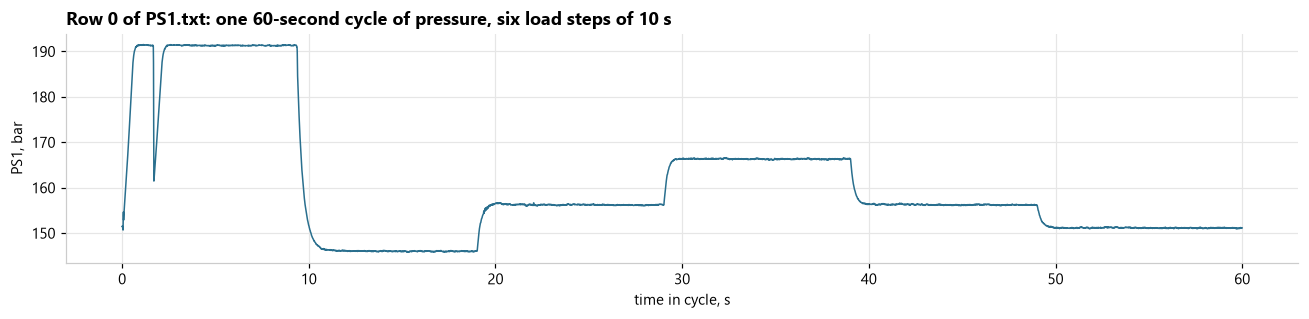

In [4]:
seconds = np.arange(ps1.shape[1]) / 100          # 100 Hz -> seconds

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(seconds, ps1.iloc[0], color=BLUE, lw=1)
ax.set(xlabel="time in cycle, s", ylabel="PS1, bar",
       title="Row 0 of PS1.txt: one 60-second cycle of pressure, six load steps of 10 s")
fig.tight_layout()
plt.show()

Now a temperature file.

In [5]:
ts1 = pd.read_csv(DATA / "TS1.txt", sep="\t", header=None)
print(ts1.shape)
ts1.iloc[:5, :8]

(2205, 60)


,0,1,2,3,4,5,6,7
0,35.570,35.492,35.469,35.422,35.414,35.320,35.227,35.242
1,36.156,36.094,35.992,36.008,35.992,35.902,35.824,35.820
2,37.488,37.391,37.340,37.312,37.223,37.145,37.059,36.973
3,38.633,38.535,38.469,38.379,38.297,38.223,38.125,38.062
4,39.461,39.461,39.375,39.281,39.203,39.113,39.043,38.969


The same layout and 2205 rows, but only **60 columns**: one reading per second. The sensors are
logged at different rates, so the files have different widths and cannot be glued into one
table as they are. A few cells further down, averaging each cycle solves that.

Look down the first column: 35.6, 36.2, 37.5, 38.6, 39.5 °C. In the first cycles of the
experiment the oil is still warming up. These cycles come back in section 2.4.

And the small file:

In [6]:
profile = pd.read_csv(DATA / "profile.txt", sep="\t", header=None)
print(profile.shape)
profile.head()

(2205, 5)


,0,1,2,3,4
0,3,100,0,130,1
1,3,100,0,130,1
2,3,100,0,130,1
3,3,100,0,130,1
4,3,100,0,130,1


2205 rows again, one per cycle, and five columns of integers without names. The names and the
meaning of every value are in `documentation.txt`:

| column | name | values |
|---|---|---|
| 0 | `cooler` | 3 % close to total failure, 20 % reduced efficiency, 100 % full efficiency |
| 1 | `valve` | 100 % optimal switching, 90 small lag, 80 severe lag, 73 close to failure |
| 2 | `pump` | internal leakage: 0 none, 1 weak, 2 severe |
| 3 | `accumulator` | 130 bar optimal, 115 slightly reduced, 100 severely reduced, 90 close to failure |
| 4 | `stable` | 0 the rig had reached steady state, 1 it may not have reached it yet |

These are the true conditions. Give the columns their names.

In [7]:
STATES = ["cooler", "valve", "pump", "accumulator", "stable"]
profile.columns = STATES

for c in STATES:
    print(f"{c:12s}", profile[c].value_counts().sort_index().to_dict())

cooler       {3: 732, 20: 732, 100: 741}
valve        {73: 360, 80: 360, 90: 360, 100: 1125}
pump         {0: 1221, 1: 492, 2: 492}
accumulator  {90: 808, 100: 399, 115: 399, 130: 599}
stable       {0: 1449, 1: 756}


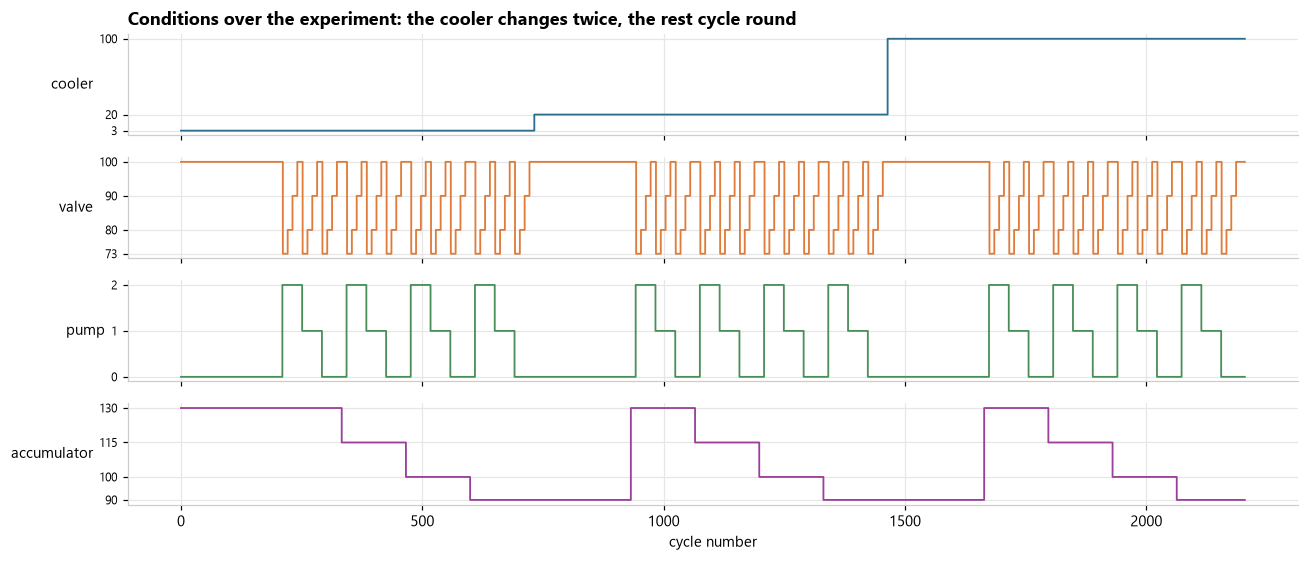

In [8]:
# one colour per group, for all the plots below
PALETTE = [BLUE, ORANGE, GREEN, PURPLE, RED, "#b8860b", "#5f9ea0", "#8b4513", GREY]

# the experiment was run in blocks: each condition was held for many cycles in a row
fig, axes = plt.subplots(4, 1, figsize=(12, 5.2), sharex=True)
for ax, c, color in zip(axes, STATES[:4], PALETTE):
    ax.step(profile.index, profile[c], where="post", color=color, lw=1.2)
    ax.set_ylabel(c, rotation=0, ha="right", va="center")
    ax.set_yticks(sorted(profile[c].unique()))
    ax.tick_params(axis="y", labelsize=8)
axes[-1].set(xlabel="cycle number")
axes[0].set(title="Conditions over the experiment: "
                  "the cooler changes twice, the rest cycle round")
fig.tight_layout()
plt.show()

The cooler sits at 3 % for cycles 0–731, at 20 % for 732–1463 and at 100 % for 1464–2204. The
other three components cycle through their states inside each block.

Keep this picture in mind. Neighbouring cycles share almost everything, and that has
consequences for every split of the data.

### All seventeen sensors

`documentation.txt` also lists what each of the 17 sensor files measures:

| file | quantity | unit | rate | columns |
|---|---|---|---|---|
| `PS1`–`PS6` | pressure | bar | 100 Hz | 6000 |
| `EPS1` | motor power | W | 100 Hz | 6000 |
| `FS1`, `FS2` | volume flow | l/min | 10 Hz | 600 |
| `TS1`–`TS4` | temperature | °C | 1 Hz | 60 |
| `VS1` | vibration | mm/s | 1 Hz | 60 |
| `CE` | cooling efficiency, virtual (computed from other signals) | % | 1 Hz | 60 |
| `CP` | cooling power, virtual (computed from other signals) | kW | 1 Hz | 60 |
| `SE` | efficiency factor | % | 1 Hz | 60 |

Every file has the layout we just saw, so all 17 are read the same way. They go into one
dictionary: `raw["PS1"]` is the 2205 × 6000 array of `PS1`, `raw["TS1"]` the 2205 × 60 array
of `TS1`, and so on.

In [9]:
SENSORS = ["PS1", "PS2", "PS3", "PS4", "PS5", "PS6", "EPS1", "FS1", "FS2",
           "TS1", "TS2", "TS3", "TS4", "VS1", "CE", "CP", "SE"]

# float32 instead of the default float64: half the memory, about 400 MB for all 17
raw = {s: pd.read_csv(DATA / f"{s}.txt", sep="\t", header=None).to_numpy(np.float32)
       for s in SENSORS}

for s, x in raw.items():
    rows, cols = x.shape
    print(f"{s:5s} {rows} cycles x {cols:4d} samples = {cols // 60:3d} Hz")

PS1   2205 cycles x 6000 samples = 100 Hz
PS2   2205 cycles x 6000 samples = 100 Hz
PS3   2205 cycles x 6000 samples = 100 Hz
PS4   2205 cycles x 6000 samples = 100 Hz
PS5   2205 cycles x 6000 samples = 100 Hz
PS6   2205 cycles x 6000 samples = 100 Hz
EPS1  2205 cycles x 6000 samples = 100 Hz
FS1   2205 cycles x  600 samples =  10 Hz
FS2   2205 cycles x  600 samples =  10 Hz
TS1   2205 cycles x   60 samples =   1 Hz
TS2   2205 cycles x   60 samples =   1 Hz
TS3   2205 cycles x   60 samples =   1 Hz
TS4   2205 cycles x   60 samples =   1 Hz
VS1   2205 cycles x   60 samples =   1 Hz
CE    2205 cycles x   60 samples =   1 Hz
CP    2205 cycles x   60 samples =   1 Hz
SE    2205 cycles x   60 samples =   1 Hz


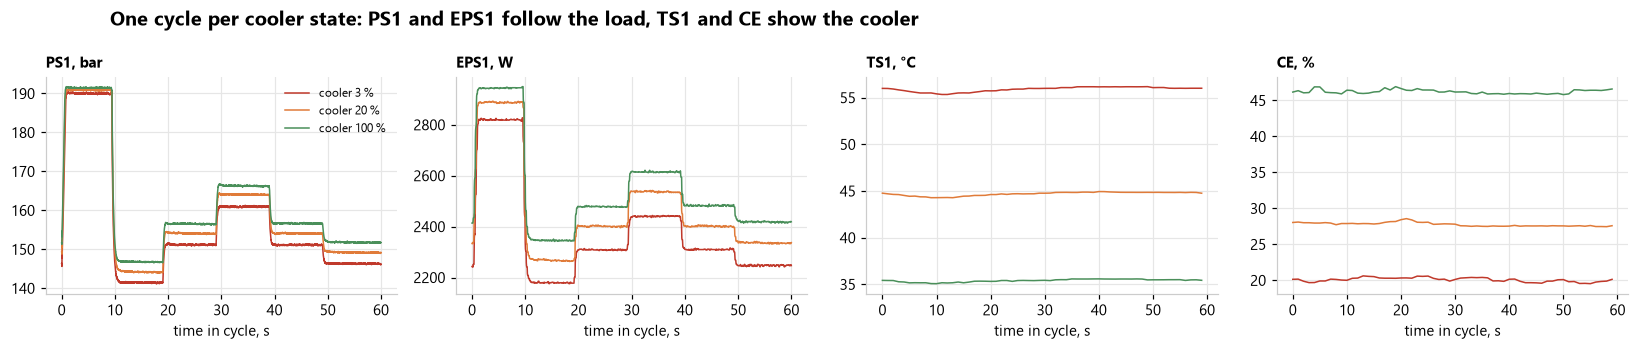

In [10]:
# one cycle for each cooler state; valve, pump and accumulator are the same in all three,
# so every difference between the three lines comes from the cooler
same = profile.query("valve == 100 and pump == 0 and accumulator == 90 and stable == 0")
pick = same.groupby("cooler").head(1)

units = {"PS1": "bar", "EPS1": "W", "TS1": "°C", "CE": "%"}

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (s, unit) in zip(axes, units.items()):
    for (i, row), color in zip(pick.iterrows(), [RED, ORANGE, GREEN]):
        x = raw[s][i]
        t = np.arange(len(x)) * 60 / len(x)          # seconds, whatever the sampling rate
        ax.plot(t, x, color=color, lw=1, label=f"cooler {row.cooler} %")
    ax.set_title(f"{s}, {unit}", fontsize=10)
    ax.set(xlabel="time in cycle, s")
axes[0].legend(fontsize=8)

title = ("One cycle per cooler state: "
         "PS1 and EPS1 follow the load, TS1 and CE show the cooler")
fig.suptitle(title, x=0.07, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

Three cycles, one for each cooler state. Valve, pump and accumulator are the same in all three,
so whatever differs between the lines comes from the cooler.

Cover the legend and try to tell which line is which cooler.

- `PS1` and `EPS1`: hard. All three lines draw the same staircase. The staircase is the load
  program of the rig, the same in every cycle. The cooler moves the lines only a little, by
  about 5 bar and 150 W, while the staircase itself spans 140 to 190 bar.
- `TS1` and `CE`: easy. The lines are almost flat and far apart. The oil is at about 35 °C
  with a good cooler, 45 °C at 20 % and 56 °C at 3 %. The cooling efficiency is about 46, 28
  and 20 %. A weak cooler removes less heat, so the oil runs hotter.

A flat line carries one piece of information: its height. The 60 readings of `TS1` in a cycle
are all nearly the same number, so replacing them by their mean loses almost nothing. A mean of
56 °C says "cooler 3 %", a mean of 35 °C says "cooler 100 %".

The mean also fixes the width problem. `PS1` has 6000 numbers per cycle and `TS1` has 60, but
each has exactly one mean. With one mean per sensor, all 17 sensors fit into one table: 2205
rows (cycles) × 17 columns (sensors).

In [11]:
# one number per sensor per cycle: the mean over the 60 s of the cycle
means = pd.DataFrame({s: x.mean(axis=1) for s, x in raw.items()})

print(means.shape)
means.describe().T

(2205, 17)


,count,mean,std,min,25%,50%,75%,max
PS1,"2,205.000",160.485,4.699,155.392,158.100,158.961,161.001,180.923
PS2,"2,205.000",109.380,4.987,104.406,106.962,107.730,109.422,131.589
PS3,"2,205.000",1.753,0.252,0.840,1.730,1.780,1.932,2.023
PS4,"2,205.000",2.600,4.279,0.000,0.000,0.000,3.503,10.207
PS5,"2,205.000",9.163,0.576,8.366,8.547,9.116,9.844,9.979
PS6,"2,205.000",9.079,0.550,8.322,8.487,9.032,9.729,9.857
EPS1,"2,205.000","2,495.562",73.839,"2,361.802","2,442.992","2,480.997","2,548.276","2,740.717"
FS1,"2,205.000",6.199,1.033,2.019,6.392,6.577,6.658,6.723
FS2,"2,205.000",9.649,0.449,8.858,9.203,9.692,10.155,10.403
TS1,"2,205.000",45.425,7.992,35.314,36.237,44.837,54.104,57.899


### How strongly do the sensors move together

Take two sensors and their means over the 2205 cycles, $x_i$ and $y_i$. The **correlation
coefficient** measures how close the points $(x_i, y_i)$ lie to a straight line:

$$r = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{\sqrt{\sum_i (x_i - \bar x)^2 \cdot \sum_i (y_i - \bar y)^2}}$$

Put the centred values of each sensor into a vector with one entry per cycle. Then $r$ is the
cosine of the angle between the two vectors, so it is always between −1 and +1.

| $r$ | meaning |
|---|---|
| +1 | the two rise together; the points lie exactly on a rising line |
| −1 | one rises while the other falls; the points lie exactly on a falling line |
| 0 | no straight-line relation |

The sign gives the direction, $|r|$ the strength. To find duplicate sensors only the strength
matters: when $|r|$ is close to 1, one sensor can be computed from the other with a straight
line, whichever way the line slopes, and the second sensor adds almost nothing.

17 sensors make $17 \cdot 16 / 2 = 136$ pairs. The cell below draws $r$ for all of them and
counts the pairs with $|r| > 0.95$.

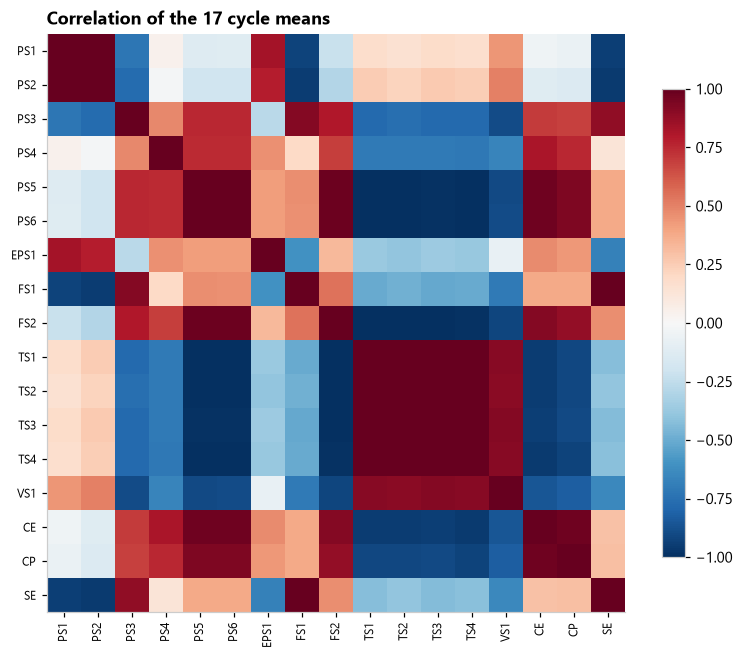

pairs with |r| > 0.95: 28 of 136

|r| with TS1, largest first:
TS1   1.000
TS3   1.000
TS2   0.999
TS4   0.999
FS2   0.995
PS5   0.993
PS6   0.993
CE    0.946


In [12]:
corr = means.corr()

fig, ax = plt.subplots(figsize=(7.2, 6.0))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(SENSORS)), SENSORS, rotation=90, fontsize=8)
ax.set_yticks(range(len(SENSORS)), SENSORS, fontsize=8)
ax.grid(False)
ax.set_title("Correlation of the 17 cycle means")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

# keep the cells above the diagonal: each pair of sensors once
above_diagonal = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.abs().where(above_diagonal).stack().dropna()
print("pairs with |r| > 0.95:", (pairs > 0.95).sum(), "of", len(pairs))

print("\n|r| with TS1, largest first:")
with_ts1 = corr["TS1"].abs().sort_values(ascending=False)
print(with_ts1.head(8).round(3).to_string())

Look at the block of dark cells around `TS1`–`TS4`. Dark red means two sensors rise together,
dark blue means one rises while the other falls. Either way the two sensors carry the same
information.

The four temperatures, the pressures `PS5` and `PS6` and the flow `FS2` move together with
$|r| \ge 0.99$: when the temperatures go up, `PS5`, `PS6` and `FS2` go down. `CE` follows at
0.95. All of them react to one physical quantity, the temperature of the oil. Seventeen sensors,
but far fewer independent signals.

Remember this group. When K-means measures a distance, the oil temperature is counted seven
times.

## 1.5 One table, many models: the problem statement in code

Same features, same answer, six models. The target is the accumulator condition, the hardest of
the four. The metric is plain accuracy for now; Lecture 5 explains why accuracy is usually the
wrong metric for failures.

In [13]:
import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

X = means.to_numpy()
y = profile["accumulator"].to_numpy()

MODELS = {
    "logistic regression": LogisticRegression(max_iter=3000),
    "kNN, k=5":            KNeighborsClassifier(),
    "decision tree":       DecisionTreeClassifier(random_state=0),
    "random forest":       RandomForestClassifier(200, random_state=0, n_jobs=-1),
    "SVM, RBF kernel":     SVC(),
    "MLP, 64 neurons":     MLPClassifier((64,), max_iter=800, random_state=0),
}

shuffled = StratifiedKFold(5, shuffle=True, random_state=0)
table = {}
for name, model in MODELS.items():
    t0 = time.time()
    acc = cross_val_score(make_pipeline(StandardScaler(), model), X, y, cv=shuffled)
    table[name] = {"accuracy": acc.mean(), "seconds": time.time() - t0}

table = pd.DataFrame.from_dict(table, orient="index").rename_axis("model")
print("accumulator condition, 4 classes, 5-fold CV with shuffling")
print(table.round(3).to_string())

accumulator condition, 4 classes, 5-fold CV with shuffling
                     accuracy  seconds
model                                 
logistic regression     0.634    0.425
kNN, k=5                0.938    0.168
decision tree           0.943    0.123
random forest           0.981    2.239
SVM, RBF kernel         0.609    0.590
MLP, 64 neurons         0.873   11.941


In [14]:
# the same label as a number: regression instead of classification
REGRESSORS = {
    "linear regression": LinearRegression(),
    "kNN, k=5":          KNeighborsRegressor(),
    "random forest":     RandomForestRegressor(200, random_state=0, n_jobs=-1),
}
print("accumulator pressure in bar, MAE, 5-fold CV with shuffling")
for name, model in REGRESSORS.items():
    pipe = make_pipeline(StandardScaler(), model)
    folds = KFold(5, shuffle=True, random_state=0)
    scores = cross_val_score(pipe, X, y, cv=folds, scoring="neg_mean_absolute_error")
    mae = -scores
    print(f"  {name:18s} {mae.mean():5.2f} bar")

accumulator pressure in bar, MAE, 5-fold CV with shuffling
  linear regression   8.85 bar
  kNN, k=5            1.44 bar


  random forest       1.30 bar


Logistic regression draws straight boundaries and stays near 0.63. The SVM with default
settings is no better, at 0.61. Neighbours and a single tree reach 0.94, and the forest looks
close to perfect at 0.98. As a regression, the linear model misses by 9 bar and the forest by
1.3 bar.

Now change one thing: the definition of a new case. Instead of shuffling cycles, cut the
experiment into five consecutive stretches and test on a stretch the model has never seen.

In [15]:
forest = make_pipeline(StandardScaler(),
                       RandomForestClassifier(200, random_state=0, n_jobs=-1))

shuffled_folds = StratifiedKFold(5, shuffle=True, random_state=0)
block_folds = KFold(5, shuffle=False)
acc_shuffled = cross_val_score(forest, X, y, cv=shuffled_folds)
acc_blocks = cross_val_score(forest, X, y, cv=block_folds)

print("random forest, accumulator condition")
print(f"  shuffled cycles      : {acc_shuffled.mean():.3f}"
      f"   folds {acc_shuffled.round(2)}")
print(f"  consecutive stretches: {acc_blocks.mean():.3f}"
      f"   folds {acc_blocks.round(2)}")

random forest, accumulator condition
  shuffled cycles      : 0.981   folds [1.   0.96 0.98 0.98 0.98]
  consecutive stretches: 0.195   folds [0.02 0.23 0.12 0.44 0.17]


Same model, same data, very different numbers. With shuffling, every test cycle has a
neighbour in training that is nearly a copy of it, so the test measures memory. With
consecutive stretches the model meets combinations of conditions it has not seen. Cooler 3 %
with the accumulator at 130 bar, for example, exists only in the first stretch. The score
collapses.

Neither number is "the" accuracy; they answer different questions. Which one you report is part
of the problem statement and has to be decided before the model. The second number is closer to
what happens when the model is installed on a plant.

---

# Part 2. Clustering in practice

## 2.1 The clustering problem

Given $n$ objects $\mathbf{x}_1, \dots, \mathbf{x}_n$ and no answers, split them into groups so
that objects inside a group are similar and objects in different groups are not.

Three things make it harder than it sounds.

- "Similar" has to be defined. Almost always it is a distance, usually the Euclidean one,
  $\lVert \mathbf{x}_i - \mathbf{x}_j \rVert = \sqrt{\sum_m (x_{im} - x_{jm})^2}$, and everything
  below depends on it.
- The number of groups is unknown. It is part of the answer.
- There is no single right answer. The same cycles can be grouped by cooler state or by pump
  state, and the algorithm finds the grouping that its distance favours.

On a plant, clustering is used to find operating regimes in a historian, to split data before
fitting one model per regime, and to show an engineer "your data has four kinds of cycle, look
at these".

## 2.2 Scaling decides what "close" means

`EPS1` is in watts, and its cycle mean varies by tens of watts. `VS1` is in mm/s and varies by
hundredths. Each sensor adds its squared difference to the distance, in its own units, so
without scaling the Euclidean distance is almost entirely the motor power.

To score a partition against known labels we use **ARI**, the adjusted Rand index. Take every
pair of cycles and ask: are they together in both partitions, or apart in both? The share of
pairs on which the partitions agree is the Rand index. ARI subtracts what two random partitions
with the same group sizes would score and rescales, so that

- ARI = 1: the same partition (the cluster numbers may differ, that does not matter);
- ARI ≈ 0: no better than random groups of the same sizes.

In real work there are no labels and no ARI. Here we have them, so we use ARI to see what each
method finds.

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

share = means.var() / means.var().sum()
top4 = share.sort_values(ascending=False).head(4) * 100
print("share of the total variance, raw units:")
print(top4.round(1).astype(str).add(" %").to_string())

scaler = StandardScaler().fit(means)
Z = scaler.transform(means)                        # every sensor: mean 0, std 1

kmeans_on = {"raw units": means.to_numpy(), "z-scores": Z}
labels_on = {name: KMeans(4, n_init=10, random_state=0).fit_predict(data)
             for name, data in kmeans_on.items()}
for name, lab in labels_on.items():
    ari = adjusted_rand_score(profile["cooler"], lab)
    print(f"\nK-means k=4 on {name}: ARI against the cooler label = {ari:.3f}")
    table = pd.crosstab(profile["cooler"], lab, rownames=["cooler"], colnames=["cluster"])
    print(table.to_string())

power_only = KMeans(4, n_init=10, random_state=0).fit_predict(means[["EPS1"]])
print(f"\nARI between 'raw units, 17 sensors' and 'EPS1 alone': "
      f"{adjusted_rand_score(labels_on['raw units'], power_only):.3f}")

share of the total variance, raw units:
EPS1    91.3 %
CE       2.2 %
SE       1.3 %
TS4      1.1 %



K-means k=4 on raw units: ARI against the cooler label = 0.816
cluster    0    1    2    3
cooler                     
3         24  464  230   14
20       712   20    0    0
100        5    0    0  736

K-means k=4 on z-scores: ARI against the cooler label = 0.845
cluster    0    1    2    3
cooler                     
3          1   25  240  466
20         0  723    0    9
100      740    1    0    0

ARI between 'raw units, 17 sensors' and 'EPS1 alone': 0.999


In raw units, 91 % of the variance is the motor power. The last line shows what that means:
K-means on all 17 raw sensors gives practically the same partition as K-means on `EPS1` alone
(ARI 0.999). The other sixteen sensors were ignored. The cooler still comes out fairly well, but
only because the motor power happens to shift with the cooler state. On another data set there
is no reason to expect that.

After z-scoring, each sensor has one unit of variance and one vote, and ARI rises from 0.82 to
0.85.

## 2.3 K-means

K-means looks for $k$ centres $\boldsymbol{\mu}_1, \dots, \boldsymbol{\mu}_k$ and an assignment
of every point to one of them that makes the total squared distance, the **inertia**, as small
as possible:

$$J = \sum_{j=1}^{k} \sum_{i \in C_j} \lVert \mathbf{x}_i - \boldsymbol{\mu}_j \rVert^2$$

Lloyd's algorithm does it in two alternating steps:

1. **assign**: each point goes to its nearest centre;
2. **update**: each centre moves to the mean of the points assigned to it.

Repeat until nothing changes. Neither step can raise $J$. With the centres fixed, sending every
point to its nearest centre minimises each term separately. With the groups fixed, the point
that minimises $\sum_{i \in C_j} \lVert \mathbf{x}_i - \boldsymbol{\mu} \rVert^2$ is the mean of
the group: the gradient $-2\sum_i (\mathbf{x}_i - \boldsymbol{\mu})$ is zero there. $J$ can
only fall, and there are finitely many partitions, so the algorithm stops. It can stop in a poor
local minimum, which is why `n_init=10` restarts it ten times and keeps the best.

The boundary between two centres is the set of points at equal distance from both: a
hyperplane, perpendicular to the segment between the centres. So K-means always cuts space into
convex cells with straight walls. Section 2.4 shows where that fails.

Here is Lloyd's algorithm by hand, on two sensors. To make the centres travel, the start is bad
on purpose: three cycles from the same 20 % block, numbers 800, 900 and 1000.

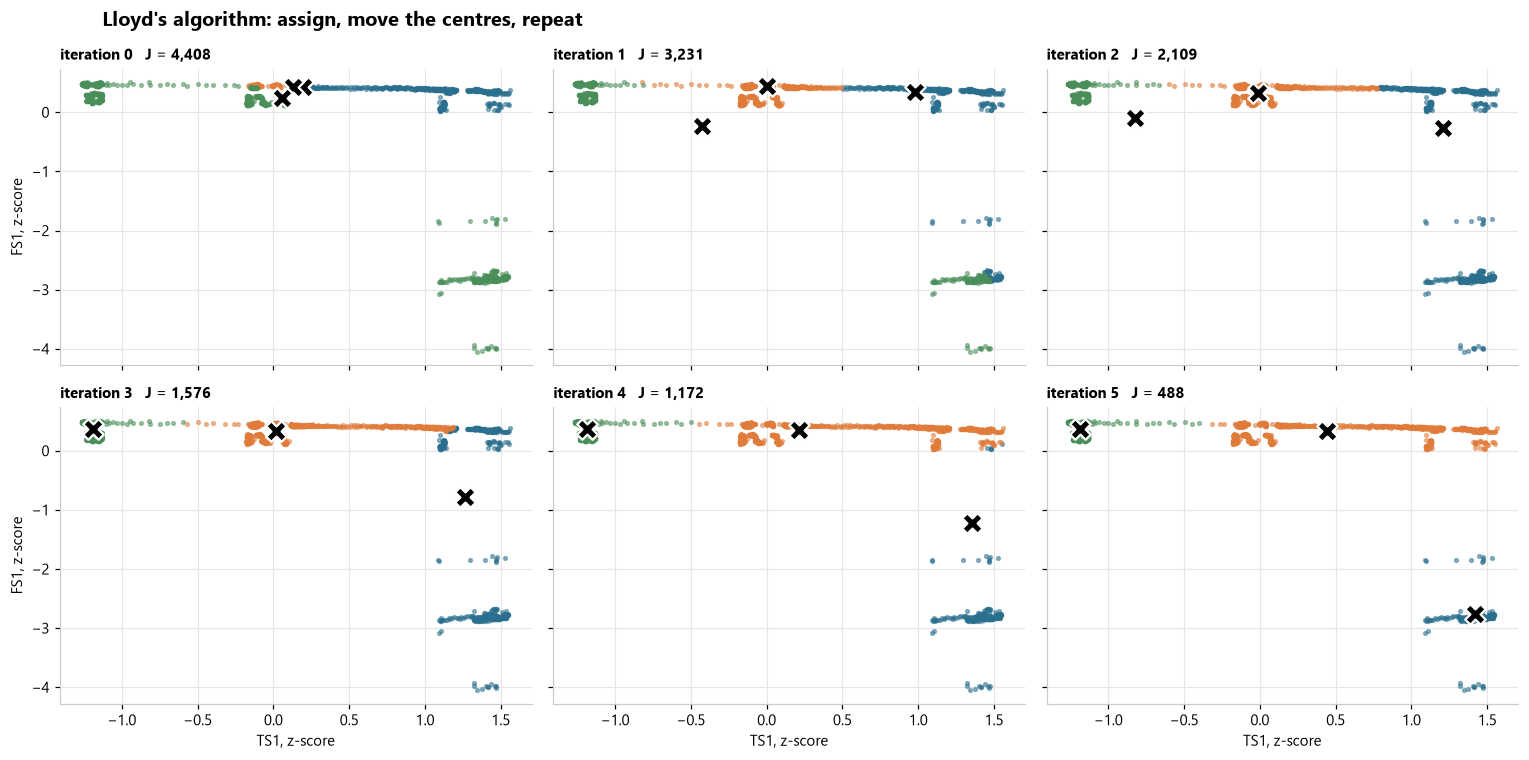

In [17]:
pair = StandardScaler().fit_transform(means[["TS1", "FS1"]])
centres = pair[[800, 900, 1000]]                     # (3, 2): three starting centres

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True)
for it, ax in enumerate(axes.ravel()):
    # 1. assign: distance from every point to every centre, take the nearest
    diff = pair[:, None, :] - centres[None, :, :]                 # (n, 3, 2)
    d = np.linalg.norm(diff, axis=2)                              # (n, 3)
    lab = d.argmin(axis=1)
    inertia = (d.min(axis=1) ** 2).sum()

    for j in range(3):
        ax.scatter(*pair[lab == j].T, s=6, color=PALETTE[j], alpha=0.5)
    ax.scatter(*centres.T, s=180, marker="X", color="black", edgecolor="white", lw=1.5)
    ax.set_title(f"iteration {it}   J = {inertia:,.0f}", fontsize=10)

    # 2. update: each centre moves to the mean of its points
    centres = np.array([pair[lab == j].mean(axis=0) for j in range(3)])

for ax in axes[-1]:
    ax.set(xlabel="TS1, z-score")
for ax in axes[:, 0]:
    ax.set(ylabel="FS1, z-score")
fig.suptitle("Lloyd's algorithm: assign, move the centres, repeat", x=0.07, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

The crosses crawl from one block to the three groups, and $J$ falls at every step, from about
4400 to under 500. scikit-learn does exactly this, faster and with a smarter start
(`k-means++`).

**Lloyd's algorithm always stops. Does it always stop at the best partition?**

<details><summary>Answer</summary>

No. It stops, because $J$ can never grow. In the assign step every point moves to its nearest
centre, so its own term $\lVert \mathbf{x}_i - \mathbf{c}_j \rVert^2$ can only shrink. In the
update step the groups are fixed, and for a fixed group the mean is the point with the
smallest sum of squared distances, so moving the centre there cannot raise $J$ either. If a
point switches only to a centre that is strictly closer, every pass that changes a label
lowers $J$, so no partition comes back twice. There are finitely many ways to split $n$
points into $k$ groups, so the loop must end.

It ends where neither step helps: a local minimum, which depends on the start. That is why
`KMeans` runs `n_init` starts and keeps the one with the smallest $J$. The cell below runs
ten single starts from random centres on the 17 z-scored sensors.

</details>

In [18]:
# ten single runs from random starting centres, without k-means++
runs = {}
for seed in range(10):
    km = KMeans(4, init="random", n_init=1, random_state=seed).fit(Z)
    runs[seed] = {"J": round(km.inertia_), "iterations": km.n_iter_}

runs = pd.DataFrame.from_dict(runs, orient="index").rename_axis("seed")
print(runs.to_string())

          J  iterations
seed                   
0      1840           4
1      4870           6
2      1840           5
3      1840           5
4     17115           5
5      4386           3
6     13730           5
7      4386           7
8     17115           3
9      1840           5


### Choosing $k$: the elbow and the silhouette

Inertia always falls when $k$ grows: with $k = n$ it is zero. The **elbow rule** looks for the
$k$ after which extra clusters stop buying much.

The **silhouette** asks each point a direct question. With $a(i)$ the mean distance from point
$i$ to the other points of its own cluster, and $b(i)$ the mean distance to the points of the
nearest other cluster,

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\ b(i)\}} \in [-1,\ 1].$$

- $s \approx 1$: the point is far from the neighbouring cluster, well placed;
- $s \approx 0$: it lies on the border;
- $s < 0$: it is closer to another cluster than to its own.

The silhouette of a partition is the mean of $s(i)$ over all points. It compares the size of
each cluster with the gap to the next one, so it rewards compact groups that are far apart.

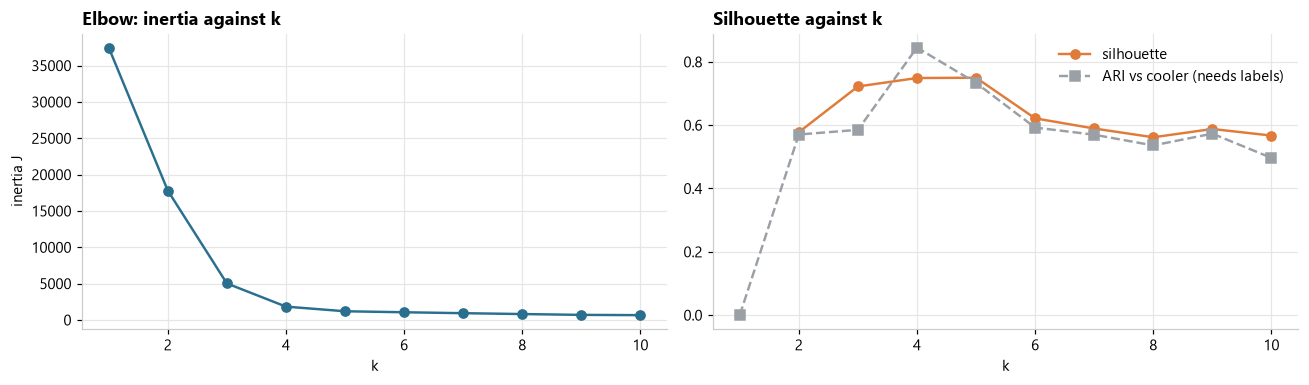

      inertia  silhouette  ARI cooler
k                                    
1  37,484.996         NaN       0.000
2  17,801.004       0.578       0.571
3   5,029.682       0.722       0.585
4   1,840.381       0.749       0.845
5   1,199.413       0.750       0.733
6   1,063.535       0.622       0.592
7     936.438       0.590       0.570
8     816.395       0.562       0.536
9     703.397       0.588       0.573
10    667.151       0.567       0.497


In [19]:
from sklearn.metrics import silhouette_score, silhouette_samples

K = range(1, 11)
by_k = {}
for k in K:
    km = KMeans(k, n_init=10, random_state=0).fit(Z)
    # the silhouette needs at least two clusters
    silhouette = silhouette_score(Z, km.labels_) if k > 1 else np.nan
    by_k[k] = {"inertia": km.inertia_,
               "silhouette": silhouette,
               "ARI cooler": adjusted_rand_score(profile["cooler"], km.labels_)}
by_k = pd.DataFrame.from_dict(by_k, orient="index").rename_axis("k")

fig, (ax_elbow, ax_sil) = plt.subplots(1, 2, figsize=(12, 3.6))
ax_elbow.plot(K, by_k["inertia"], "o-", color=BLUE)
ax_elbow.set(xlabel="k", ylabel="inertia J", title="Elbow: inertia against k")

ax_sil.plot(K, by_k["silhouette"], "o-", color=ORANGE, label="silhouette")
ax_sil.plot(K, by_k["ARI cooler"], "s--", color=GREY,
            label="ARI vs cooler (needs labels)")
ax_sil.set(xlabel="k", title="Silhouette against k")
ax_sil.legend()
fig.tight_layout()
plt.show()

print(by_k.round(3).to_string())

The elbow is at $k = 4$: from 3 to 4 clusters the inertia falls by 3189, almost two thirds. The
fifth cluster removes 641 more, and every cluster after that about 100. The silhouette peaks at
4–5 with about 0.75, which is high for real data.

The two rules agree here. They will not always, and in the practice they do not.

Every point's silhouette, for $k = 4$:

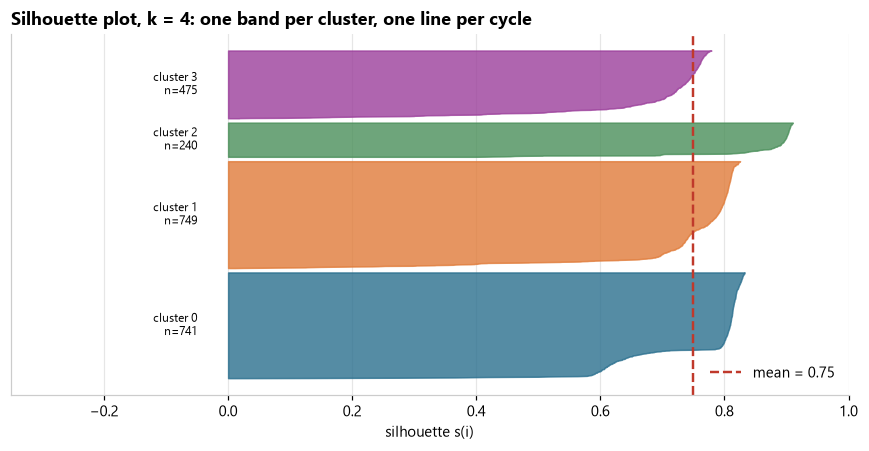

cluster    0    1    2    3
cooler                     
3          1   25  240  466
20         0  723    0    9
100      740    1    0    0
ARI vs cooler: 0.845


In [20]:
km4 = KMeans(4, n_init=10, random_state=0).fit(Z)
s = silhouette_samples(Z, km4.labels_)

fig, ax = plt.subplots(figsize=(8, 4.2))
y0 = 0
for j in range(4):
    sj = np.sort(s[km4.labels_ == j])
    ax.fill_betweenx(np.arange(y0, y0 + len(sj)), 0, sj, color=PALETTE[j], alpha=0.8)
    ax.text(-0.05, y0 + len(sj) / 2, f"cluster {j}\nn={len(sj)}",
            ha="right", va="center", fontsize=8)
    y0 += len(sj) + 30          # a gap between the bands
ax.axvline(s.mean(), color=RED, ls="--", label=f"mean = {s.mean():.2f}")
ax.set_yticks([])
ax.set(xlim=(-0.35, 1), xlabel="silhouette s(i)",
       title="Silhouette plot, k = 4: one band per cluster, one line per cycle")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

print(pd.crosstab(profile["cooler"], km4.labels_,
                  rownames=["cooler"], colnames=["cluster"]))
print("ARI vs cooler:", round(adjusted_rand_score(profile["cooler"], km4.labels_), 3))

The 20 % and the 100 % coolers each get their own cluster. The 3 % cooler is split in two. The
algorithm has a reason for that; look at what separates the two halves.

In [21]:
hot = profile["cooler"] == 3
hot_clusters = km4.labels_[hot]
split = means[hot].groupby(hot_clusters)[["TS1", "CE", "SE", "FS1", "PS1"]].mean()
split["cycles"] = hot[hot].groupby(hot_clusters).size()
print("cooler 3 % only: mean of each sensor in each K-means cluster")
print(split.round(2).to_string())

print("\npump leakage inside each of them:")
leakage = pd.crosstab(profile.loc[hot, "pump"], hot_clusters,
                      rownames=["pump"], colnames=["cluster"])
print(leakage.to_string())

print("\nSE, mean per cycle, by cooler and pump leakage:")
se_by_state = means["SE"].groupby([profile["cooler"], profile["pump"]]).mean()
print(se_by_state.unstack().round(1).to_string())

cooler 3 % only: mean of each sensor in each K-means cluster
     TS1     CE     SE   FS1     PS1  cycles
0 35.620 39.600 59.160 6.710 160.670       1
1 44.670 18.660 59.810 6.670 159.190      25
2 56.750 19.270 30.200 3.280 173.010     240
3 54.630 19.740 59.380 6.530 156.720     466

pump leakage inside each of them:
cluster  0   1    2    3
pump                    
0        1  25   15  363
1        0   0  105   59
2        0   0  120   44

SE, mean per cycle, by cooler and pump leakage:
pump        0      1      2
cooler                     
3      59.000 40.300 36.900
20     59.600 57.400 56.100
100    58.900 56.700 55.500


Most of the block sits in clusters 2 and 3. In cluster 2 the efficiency factor `SE` is cut from
59 to 30 % and the flow `FS1` from 6.5 to 3.3 l/min, and 225 of its 240 cycles have a leaking
pump. Clusters 0 and 1 hold cycles 0–25, the warm-up at the start of the experiment: `TS1` is
still between 36 and 45 °C there.

The last table explains why this happens only in the 3 % block. With a good cooler the leak
barely moves `SE` (59 → 56). With a nearly dead cooler the oil runs at about 55 °C, and the same
leak drops `SE` to 37–40. Hot oil is thinner, and a worn pump loses more of it through its
internal gaps.

So K-means found a real state of the machine, a failing cooler together with a leaking pump.
Our label column simply has no name for it. Checking the clusters against a single label would
have called this an error.

Cluster centres, back in physical units, are what you show an engineer:

In [22]:
centres = pd.DataFrame(scaler.inverse_transform(km4.cluster_centers_), columns=SENSORS)
centres.index.name = "cluster"
centres["cycles"] = np.bincount(km4.labels_)
shown = ["cycles", "TS1", "CE", "CP", "SE", "FS1", "PS1", "EPS1"]
print(centres[shown].round(1).to_string())

         cycles    TS1     CE    CP     SE   FS1     PS1      EPS1
cluster                                                           
0           741 35.900 46.900 2.200 57.700 6.600 160.800 2,549.100
1           749 45.400 26.900 1.700 58.400 6.500 158.500 2,463.900
2           240 56.800 19.300 1.500 30.200 3.300 173.000 2,623.400
3           475 54.600 19.900 1.500 59.400 6.500 156.700 2,397.400


## 2.4 DBSCAN

K-means assumes round groups around a centre, and it must put every point somewhere. DBSCAN
starts from density instead. It has two parameters, a radius $\varepsilon$ and a count
`min_samples`.

- A **core point** has at least `min_samples` points, itself included, within distance
  $\varepsilon$.
- A **border point** is not a core point but lies within $\varepsilon$ of one.
- **Noise** is neither. It gets the label `-1`.

A cluster is everything you can reach by stepping from core point to core point. The number of
clusters is an output, and nothing forces an odd point into a group.

First, a case where K-means fails and DBSCAN does not:

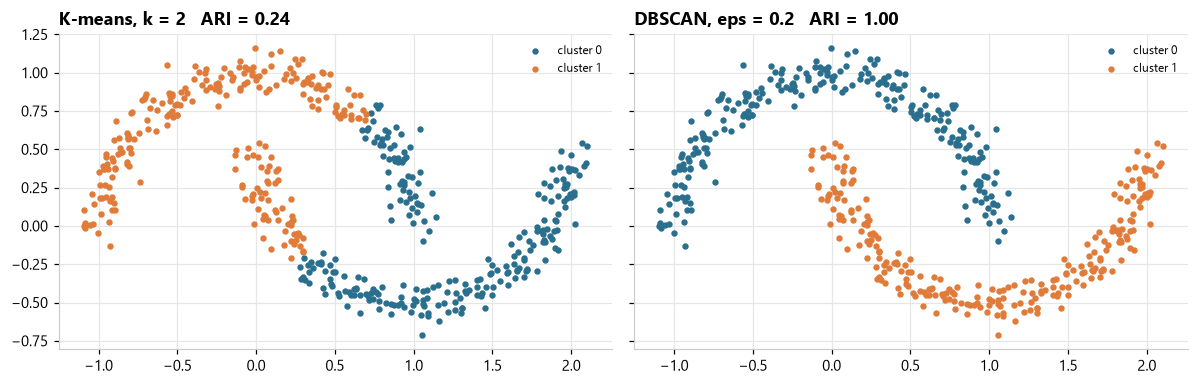

In [23]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

toy, toy_true = make_moons(500, noise=0.07, random_state=0)
toy_km = KMeans(2, n_init=10, random_state=0).fit_predict(toy)
toy_db = DBSCAN(eps=0.2, min_samples=8).fit_predict(toy)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
panels = [(toy_km, "K-means, k = 2"), (toy_db, "DBSCAN, eps = 0.2")]
for ax, (lab, title) in zip(axes, panels):
    for j in sorted(set(lab)):
        if j == -1:
            color, label = GREY, "noise"
        else:
            color, label = PALETTE[j], f"cluster {j}"
        ax.scatter(*toy[lab == j].T, s=10, color=color, label=label)
    ax.set_title(f"{title}   ARI = {adjusted_rand_score(toy_true, lab):.2f}")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

K-means cuts the moons with a straight line: with two centres, the boundary is the hyperplane
halfway between them. DBSCAN follows the density along each arc, because a chain of core points
can bend.

### Choosing $\varepsilon$: the k-distance plot

For every point take the distance to its `min_samples`-th nearest neighbour, counting the point
itself as the first, and sort these distances. Points inside clusters have small distances; the
curve bends sharply where noise begins. Put $\varepsilon$ near that bend.

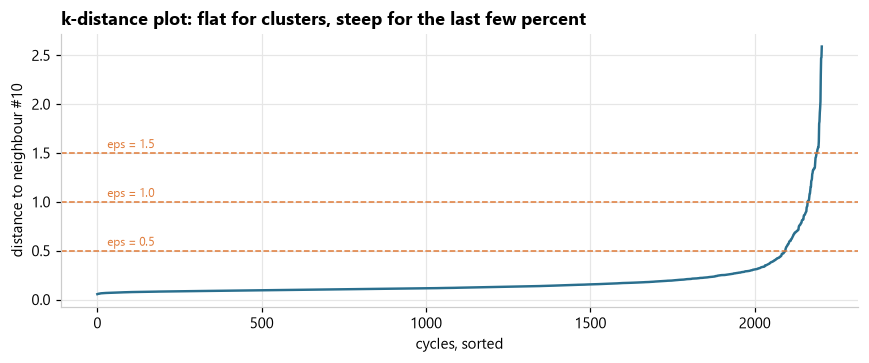

       clusters  noise  ARI cooler
eps                               
0.500         5     85       0.738
0.700         5     49       0.858
1.000         5     25       0.871
1.300         6      5       0.876
1.500         5      3       0.581
2.000         5      0       0.581


In [24]:
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 10
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z)
distances, _ = nn.kneighbors(Z)          # column 0 is the point itself, distance 0
kdist = np.sort(distances[:, -1])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(kdist, color=BLUE)
for eps in [0.5, 1.0, 1.5]:
    ax.axhline(eps, color=ORANGE, ls="--", lw=1)
    ax.text(30, eps + 0.05, f"eps = {eps}", color=ORANGE, fontsize=8)
ax.set(xlabel="cycles, sorted", ylabel=f"distance to neighbour #{MIN_SAMPLES}",
       title="k-distance plot: flat for clusters, steep for the last few percent")
fig.tight_layout()
plt.show()

sweep = {}
for eps in [0.5, 0.7, 1.0, 1.3, 1.5, 2.0]:
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Z)
    sweep[eps] = {"clusters": len(set(lab) - {-1}), "noise": (lab == -1).sum(),
                  "ARI cooler": adjusted_rand_score(profile["cooler"], lab)}
sweep = pd.DataFrame.from_dict(sweep, orient="index").rename_axis("eps")
print(sweep.round(3).to_string())

With too small an $\varepsilon$ many cycles become noise. With too large an $\varepsilon$
neighbouring states melt into one cluster. In between, from 0.7 to 1.3, the answer is stable.
We take 1.0.

In [25]:
db = DBSCAN(eps=1.0, min_samples=MIN_SAMPLES).fit(Z)
db_lab = db.labels_
print(pd.crosstab(profile["cooler"], db_lab,
                  rownames=["cooler"], colnames=["DBSCAN cluster"]))
print("ARI vs cooler:", round(adjusted_rand_score(profile["cooler"], db_lab), 3))

noise = np.flatnonzero(db_lab == -1)
# number the blocks of constant cooler state, then count the cycles inside each block
is_new_block = profile["cooler"].ne(profile["cooler"].shift())
block_id = is_new_block.cumsum()
since_change = profile.groupby(block_id).cumcount()
print(f"\n{len(noise)} noise cycles:", noise.tolist())
print("cycles since the last cooler change, for each of them:",
      since_change.iloc[noise].tolist())

DBSCAN cluster  -1    0    1   2    3    4
cooler                                    
3               18  484  219  11    0    0
20               0    1    0   0  731    0
100              7    0    0   0    0  734
ARI vs cooler: 0.871

25 noise cycles: [0, 1, 2, 3, 4, 5, 212, 214, 215, 365, 380, 419, 531, 558, 629, 635, 666, 688, 1464, 1465, 1466, 1467, 1468, 1469, 1724]
cycles since the last cooler change, for each of them: [0, 1, 2, 3, 4, 5, 212, 214, 215, 365, 380, 419, 531, 558, 629, 635, 666, 688, 0, 1, 2, 3, 4, 5, 260]


DBSCAN finds the same cooler blocks and splits the 3 % block along the same pump leak: 484
cycles without the leak, 219 plus a small group of 11 with it. And it adds something K-means
cannot: 25 noise cycles.

Look at where they are.

- Cycles 0–5: the start of the experiment, oil warming up from 36 to 41 °C.
- Cycles 1464–1469: the first six after the cooler was switched to 100 %, oil cooling down from
  45 to 40 °C.
- Ten cycles with a leaking pump in the 3 % block, on the thin edge of that group.
- Three single odd cycles: 212, 558, 1724.

DBSCAN had no clock and no labels, yet it put aside the cycles where the rig was changing
temperature. That is the practical use of the noise label: a short list of cycles for an
engineer to look at.

### Comparing two partitions

A partition has no "true" numbering, so compare two of them with a crosstab and with the ARI
between them. No labels are needed for that.

In [26]:
print(pd.crosstab(km4.labels_, db_lab, rownames=["K-means k=4"], colnames=["DBSCAN"]))
print("\nARI K-means vs DBSCAN:", round(adjusted_rand_score(km4.labels_, db_lab), 3))

agree = (pd.crosstab(km4.labels_, db_lab).max(axis=1).sum()) / len(db_lab)
print(f"cycles in the dominant DBSCAN cluster of their K-means cluster: {agree:.1%}")

DBSCAN       -1    0    1   2    3    4
K-means k=4                            
0             7    0    0   0    0  734
1             6   20    0   0  723    0
2            10    0  219  11    0    0
3             2  465    0   0    8    0

ARI K-means vs DBSCAN: 0.951
cycles in the dominant DBSCAN cluster of their K-means cluster: 97.1%


Read the crosstab row by row. Where a row has one big number, the two methods agree about that
group. Where it is spread out, they disagree, and those rows are where to look at the data.

Here the methods agree on 97 % of the cycles, with ARI 0.95. The 64 other cycles are the 25
noise cycles, the small group of 11, and 28 cycles on the border between the 3 % and 20 %
groups.

## 2.5 Hierarchical clustering, briefly

Start with every cycle as its own cluster and repeatedly merge the two closest clusters. Ward's
rule merges the pair that increases the within-cluster sum of squares $J$ the least, the same
quantity K-means minimises. Merging clusters $A$ and $B$ raises $J$ by

$$\Delta J = \frac{|A|\,|B|}{|A| + |B|}\,\lVert \boldsymbol{\mu}_A - \boldsymbol{\mu}_B \rVert^2,$$

so Ward prefers to merge small clusters with close centres. The result is a tree, the
**dendrogram**. Cut it at any height and you get a partition.

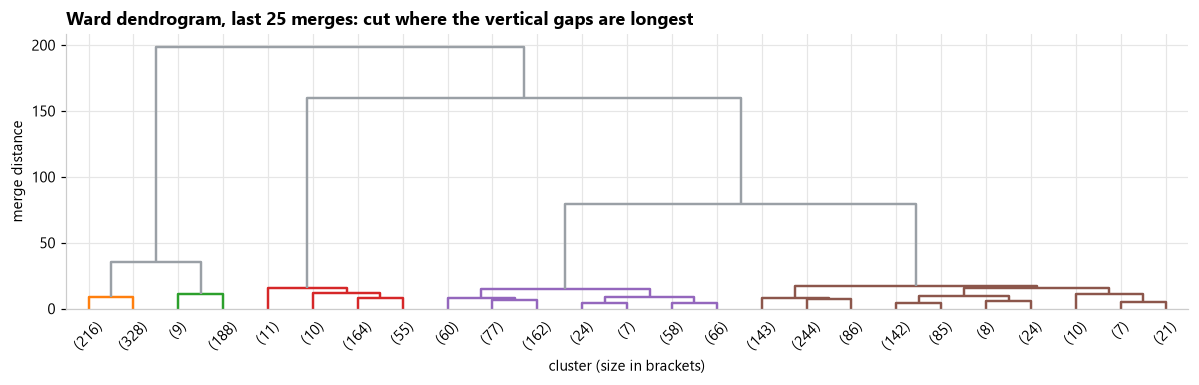

ARI hierarchical vs cooler : 0.84
ARI hierarchical vs K-means: 0.975


In [27]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

tree = linkage(Z, method="ward")

fig, ax = plt.subplots(figsize=(11, 3.6))
dendrogram(tree, truncate_mode="lastp", p=25, ax=ax, color_threshold=tree[-4, 2],
           above_threshold_color=GREY)
ax.set(xlabel="cluster (size in brackets)", ylabel="merge distance",
       title="Ward dendrogram, last 25 merges: cut where the vertical gaps are longest")
fig.tight_layout()
plt.show()

hc_lab = fcluster(tree, t=4, criterion="maxclust")
ari_cooler = adjusted_rand_score(profile["cooler"], hc_lab)
ari_kmeans = adjusted_rand_score(km4.labels_, hc_lab)
print("ARI hierarchical vs cooler :", round(ari_cooler, 3))
print("ARI hierarchical vs K-means:", round(ari_kmeans, 3))

Cut into four clusters, the tree gives almost the same partition as K-means: ARI 0.975 between
them, 0.84 against the cooler.

### Which method when

| situation | take |
|---|---|
| groups are compact, you have a rough idea of $k$ | K-means |
| odd shapes, outliers, transients you want flagged | DBSCAN |
| you want to see structure at several levels | hierarchical |
| groups overlap and you want a probability per point | Gaussian mixture (`GaussianMixture`) |
| more than about 20 features | select or reduce features first, Part 5 |

---

# Part 3. From clusters to pattern recognition

**Pattern recognition** assigns an object to one of several known classes from its features.
On a plant the classes are equipment states, and the "known" part is the expensive bit.

Clustering gives a cheap way in:

1. cluster the history with no labels;
2. an engineer inspects a few cycles of each cluster and names it;
3. every new cycle is assigned to the nearest cluster centre, and so gets a name.

Step 3 is a classifier, the *nearest-centroid* rule. Below, K-means runs on the even cycles.
Each cluster gets the most common cooler state among five of its cycles, as if an engineer had
checked five. Then the odd cycles are recognised.

In [28]:
even, odd = np.arange(0, len(Z), 2), np.arange(1, len(Z), 2)

km_train = KMeans(4, n_init=10, random_state=0).fit(Z[even])
train_lab = km_train.labels_

# the engineer looks at five cycles per cluster and writes down the cooler state
rng = np.random.default_rng(0)
name = {}
for j in range(4):
    checked = rng.choice(even[train_lab == j], 5, replace=False)
    name[j] = int(profile.loc[checked, "cooler"].mode()[0])
print("cluster -> cooler state, from 20 inspected cycles:", name)

predicted = pd.Series(km_train.predict(Z[odd])).map(name).to_numpy()
truth = profile["cooler"].iloc[odd].to_numpy()
correct = (predicted == truth).mean()
print(f"\nrecognised correctly: {correct:.1%} of {len(odd)} new cycles")
print(pd.crosstab(truth, predicted, rownames=["true"], colnames=["recognised"]))

cluster -> cooler state, from 20 inspected cycles: {0: 20, 1: 100, 2: 3, 3: 3}

recognised correctly: 98.5% of 1102 new cycles
recognised  3    20   100
true                     
3           353   13    0
20            4  362    0
100           0    0  370


Twenty labelled cycles instead of 1102, and 98.5 % of the new cycles are recognised. The two
clusters of the 3 % block both get the name "3", which is fine: two groups can share a class.
The 17 mistakes sit on the border between 3 % and 20 %.

The even/odd split is the optimistic kind from section 1.5, since every odd cycle has an even
neighbour. For the cooler it does little harm, because the three states are far apart. For the
accumulator it would give a flattering number, as section 1.5 showed.

---

# Part 4. Feature engineering

## 4.1 Principles

A feature is a number computed from raw data that the model is allowed to see. Good features
follow a few rules.

1. **Start from physics.** Ask what the fault does to the machine, then which signal shows it
   and when.
2. **Align the window with the process.** Here one object is one load cycle, and the cycle has
   six 10-second steps. A window that cuts a step in half mixes two operating points.
3. **Prefer features that survive a sensor change.** A sensor drifts by an offset (it adds a
   constant) and by a gain (it multiplies). A time is immune to both, a difference of two
   readings cancels the offset, a ratio cancels the gain. A raw level suffers from both.
4. **Keep them cheap.** A feature that has to run on a PLC every minute cannot need a GPU.
5. **Never compute a feature from the answer.** "Mean temperature of the cycles with the same
   cooler label" is leakage, however useful it looks.
6. **Check redundancy afterwards.** Ten features that measure the oil temperature are one
   feature with ten votes.

## 4.2 A fault the means do not see

The cooler was easy because it changes the level of a signal. The valve does not.

In [29]:
for target in ["cooler", "valve", "pump", "accumulator"]:
    n_states = profile[target].nunique()
    lab = KMeans(n_states, n_init=10, random_state=0).fit_predict(Z)
    ari = adjusted_rand_score(profile[target], lab)
    print(f"K-means on the 17 means, k = number of {target} states: "
          f"ARI vs {target:11s} = {ari:.3f}")

K-means on the 17 means, k = number of cooler states: ARI vs cooler      = 0.585


K-means on the 17 means, k = number of valve states: ARI vs valve       = 0.016


K-means on the 17 means, k = number of pump states: ARI vs pump        = 0.098


K-means on the 17 means, k = number of accumulator states: ARI vs accumulator = 0.076


Clustering on the averages finds the cooler and nothing else. A lagging valve switches late,
and a delay of a fraction of a second barely changes a 60-second average. Look at the moment of
switching instead.

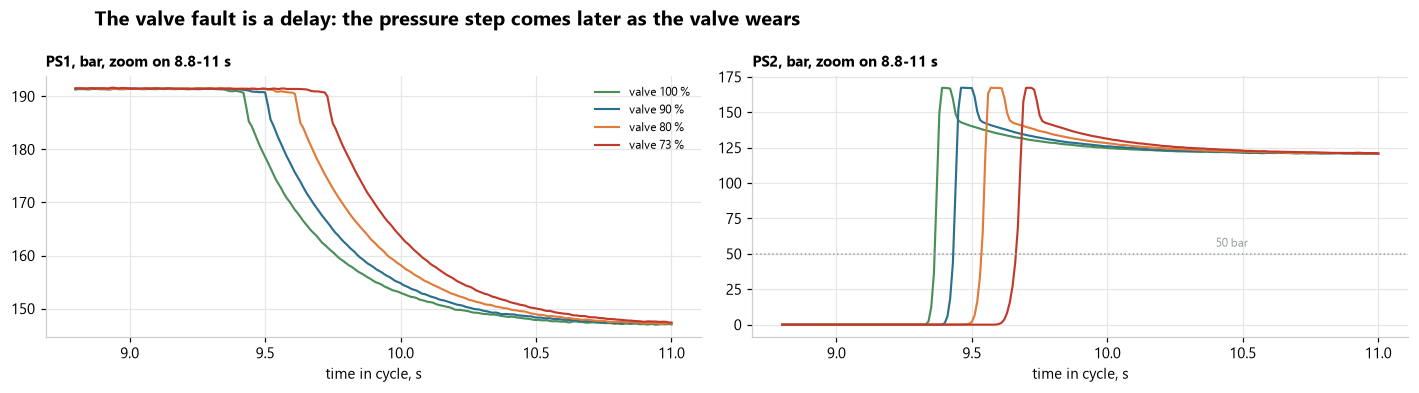

In [30]:
same = profile.query("cooler == 100 and pump == 0 and accumulator == 130 and stable == 0")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, s in zip(axes, ["PS1", "PS2"]):
    t = np.arange(raw[s].shape[1]) / 100          # 100 Hz: sample number / 100 = seconds
    win = (t >= 8.8) & (t <= 11)
    for v, color in zip([100, 90, 80, 73], [GREEN, BLUE, ORANGE, RED]):
        i = same.index[same["valve"] == v][0]
        ax.plot(t[win], raw[s][i][win], color=color, lw=1.4, label=f"valve {v} %")
    ax.set_title(f"{s}, bar, zoom on 8.8-11 s", fontsize=10)
    ax.set(xlabel="time in cycle, s")
axes[1].axhline(50, color=GREY, ls=":", lw=1)
axes[1].text(10.4, 55, "50 bar", color=GREY, fontsize=8)
axes[0].legend(fontsize=8)

title = "The valve fault is a delay: the pressure step comes later as the valve wears"
fig.suptitle(title, x=0.07, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

At about 9.4 s the valve switches and `PS2` jumps from zero to over 100 bar. The worse the
valve, the later the jump. The feature writes itself: **the time at which `PS2` first crosses
50 bar**.

`PS2` also starts every cycle high and drops to zero within the first second, so the search
starts at 5 s, sample 500.

In [31]:
def switch_time(ps2, level=50.0, start=500):
    # ps2: (cycles, 6000) at 100 Hz -> for every cycle, the time in s of the first sample
    # after `start` where PS2 is above `level` bar
    above = ps2[:, start:] > level
    assert above.any(axis=1).all(), "a cycle never crosses the level: argmax would give 0"
    first_above = np.argmax(above, axis=1) + start
    return first_above / 100


t_switch = pd.Series(switch_time(raw["PS2"]), name="t_switch")

print("switching time, s, by valve state:")
by_valve = t_switch.groupby(profile["valve"]).agg(["mean", "std", "min", "max"])
print(by_valve.round(3).to_string())

lab = KMeans(4, n_init=10, random_state=0).fit_predict(t_switch.to_frame())
ari = adjusted_rand_score(profile["valve"], lab)
print(f"\nK-means k=4 on this ONE feature: ARI vs valve = {ari:.3f}")
print(pd.crosstab(profile["valve"], lab, rownames=["valve"], colnames=["cluster"]))

switching time, s, by valve state:
       mean   std   min   max
valve                        
73    9.667 0.006 9.660 9.700
80    9.543 0.005 9.540 9.570
90    9.442 0.004 9.440 9.460
100   9.372 0.004 9.370 9.390

K-means k=4 on this ONE feature: ARI vs valve = 1.000
cluster    0     1    2    3
valve                       
73       360     0    0    0
80         0     0  360    0
90         0     0    0  360
100        0  1125    0    0


The four states sit at 9.37, 9.44, 9.54 and 9.67 s, and the spread inside each state is 5 ms.
One engineered number separates the valve perfectly, where seventeen averages gave ARI 0.02.

The delay is 70, 170 and 300 ms against a healthy valve, and the `min`/`max` columns show that
the states do not even overlap. That is why one number is enough: the gap between neighbouring
states is more than ten times the spread inside a state.

## 4.3 Generic features, when you do not know the physics

Often nobody can tell you where the fault shows. Then compute a standard set for every sensor
and let the selection in Part 5 find the useful ones:

- level: mean, min, max;
- spread: standard deviation;
- trend: the slope of a straight line through the cycle;
- shape: the mean of each of the six 10-second load steps.

That is 11 numbers per sensor, 187 in total.

In [32]:
def window_features(raw, n_seg=6):
    # raw: {sensor: (cycles, samples)} -> one row per cycle, 11 statistics per sensor;
    # the n_seg segments are the six 10-second load steps of the cycle
    out = {}
    for s, x in raw.items():
        x = x.astype(np.float64)
        t = np.arange(x.shape[1]) * 60 / x.shape[1]          # s
        out[f"{s}_mean"] = x.mean(axis=1)
        out[f"{s}_std"] = x.std(axis=1)
        out[f"{s}_min"] = x.min(axis=1)
        out[f"{s}_max"] = x.max(axis=1)
        out[f"{s}_slope"] = np.polyfit(t, x.T, 1)[0]          # per second, least squares
        for k, part in enumerate(np.array_split(x, n_seg, axis=1)):
            out[f"{s}_seg{k}"] = part.mean(axis=1)
    return pd.DataFrame(out)


wide = window_features(raw)
wide["t_switch"] = t_switch

print(wide.shape)
print(wide.iloc[:3, :12].round(3).to_string())

(2205, 188)
   PS1_mean  PS1_std  PS1_min  PS1_max  PS1_slope  PS1_seg0  PS1_seg1  PS1_seg2  PS1_seg3  PS1_seg4  PS1_seg5  PS2_mean
0   160.673   13.938  145.830  191.510     -0.404   187.363   147.027   157.070   165.545   155.869   151.167   109.467
1   160.603   14.118  145.730  191.470     -0.418   187.884   147.015   156.867   165.283   155.669   150.901   109.355
2   160.348   14.191  145.370  191.410     -0.421   187.773   146.755   156.560   165.088   155.336   150.575   109.159


---

# Part 5. Informative features

## 5.1 Why select at all

- every useless feature adds noise to the distances that K-means and DBSCAN use;
- redundant features give one physical factor several votes (section 1.4);
- fewer sensors are cheaper to install, calibrate and keep alive;
- an engineer can check a short list.

There are three families of methods:

| family | idea | example | uses the model? |
|---|---|---|---|
| filter | score each feature on its own | variance, correlation, mutual information | no |
| wrapper | try subsets, keep the one the model likes | forward selection, RFE | yes, many times |
| embedded | the model scores features while it trains | forest importance, L1 regression | yes, once |

This week is about filters.

## 5.2 Variance threshold

A feature that never changes carries no information. `VarianceThreshold` drops every column
with a variance below a limit.

In [33]:
from sklearn.feature_selection import VarianceThreshold

const = wide.columns[wide.nunique() == 1]
print("columns with a single value:", list(const))

print("\nvariance of the 17 cycle means, raw units, smallest first:")
print(means.var().sort_values().head(6).round(4).to_string())

vt = VarianceThreshold(threshold=0.01).fit(means)
dropped = list(means.columns[~vt.get_support()])
print("\nVarianceThreshold(0.01) on raw units drops:", dropped)

columns with a single value: ['PS2_min', 'PS3_min', 'SE_min']

variance of the 17 cycle means, raw units, smallest first:
VS1   0.004
PS3   0.064
CP    0.077
FS2   0.202
PS6   0.302
PS5   0.332

VarianceThreshold(0.01) on raw units drops: ['VS1']


The first line is the legitimate use. `PS2`, `PS3` and `SE` drop to zero at some moment of every
cycle, so their minimum is always 0. Those columns are constant and can go.

The last line is the trap. `VS1`, the only vibration sensor, is "dropped" because it is measured
in mm/s and its cycle means stay around 0.6. Variance has units, the square of the sensor's
unit: a threshold of 0.01 is tiny in watts squared and large in (mm/s) squared.

There are two fixes: compare variances after min-max scaling to [0, 1], or use the coefficient
of variation $\mathrm{CV} = \sigma / |\mu|$, which has no units. Never compare them after
z-scoring: then every variance is exactly 1.

In [34]:
from sklearn.preprocessing import MinMaxScaler

min_max = pd.DataFrame(MinMaxScaler().fit_transform(means), columns=SENSORS)
check = pd.DataFrame({
    "raw variance": means.var(),
    "variance after min-max": min_max.var(),
    "CV = std / |mean|": means.std() / means.mean().abs(),
})
print(check.sort_values("raw variance").round(4).to_string())

      raw variance  variance after min-max  CV = std / |mean|
VS1          0.004                   0.037              0.098
PS3          0.064                   0.045              0.144
CP           0.077                   0.024              0.154
FS2          0.202                   0.084              0.047
PS6          0.302                   0.128              0.060
PS5          0.332                   0.128              0.063
FS1          1.067                   0.048              0.167
PS4         18.313                   0.176              1.646
PS1         22.085                   0.034              0.029
PS2         24.866                   0.034              0.046
TS2         54.705                   0.123              0.147
TS3         55.531                   0.124              0.156
TS1         63.871                   0.125              0.176
TS4         65.738                   0.128              0.199
SE          80.285                   0.045              0.162
CE      

After min-max scaling every column lies between 0 and 1, and all the variances are of the same
order, 0.02 to 0.18. `VS1`, at 0.037, sits next to `PS1` and `EPS1`, and `EPS1`, by far the
largest raw variance, is now one of the smallest. On scaled data the variance threshold removes
only the columns that truly stand still.

## 5.3 Correlation filter

Of two features with $|r| > 0.95$, keep one. A greedy version walks down the list and drops a
feature if it is too correlated with one already kept.

In [35]:
def drop_correlated(df, limit=0.95):
    # greedy, in column order: the first of every correlated group survives
    kept = []
    for c in df.columns:
        if all(abs(df[c].corr(df[k])) <= limit for k in kept):
            kept.append(c)
    return kept


kept = drop_correlated(means)
print(f"kept {len(kept)} of {len(SENSORS)}:", kept)
print("dropped:", [c for c in SENSORS if c not in kept])

kept 8 of 17: ['PS1', 'PS3', 'PS4', 'PS5', 'EPS1', 'FS1', 'VS1', 'CP']
dropped: ['PS2', 'PS6', 'FS2', 'TS1', 'TS2', 'TS3', 'TS4', 'CE', 'SE']


Which feature survives depends on the column order, so the result is a starting point for an
engineer, not an answer. The kept list is still a fair summary: one oil-temperature signal
(`PS5`) stands in for the whole warm block.

## 5.4 Mutual information

Correlation sees only straight lines. **Mutual information** measures how much knowing the
feature $X$ reduces the uncertainty about the answer $Y$, whatever the shape of the relation:

$$I(X;Y) = \sum_{x}\sum_{y} p(x,y)\,\ln\frac{p(x,y)}{p(x)\,p(y)} = H(Y) - H(Y \mid X),$$

with the entropy $H(Y) = -\sum_y p(y)\ln p(y)$.

$H(Y)$ is the uncertainty about $Y$ before you look at the feature. $H(Y \mid X)$ is the
uncertainty that is left, on average, once you know $X$. The difference is what the feature
told you. If $X$ and $Y$ are independent, $p(x,y) = p(x)p(y)$, every logarithm is zero and
$I = 0$.

- $I = 0$: the feature says nothing about $Y$;
- $I = H(Y)$: the feature determines $Y$ completely. For three equal classes that ceiling is
  $\ln 3 = 1.099$ nats.

For a continuous feature the simplest estimate cuts it into bins and counts. By hand:

In [36]:
from sklearn.feature_selection import mutual_info_classif


def entropy(labels):
    p = pd.Series(labels).value_counts(normalize=True).to_numpy()
    return -(p * np.log(p)).sum()                              # nats


def binned_mi(x, y, bins=10):
    # equal-count bins of x: rank first, so that ties do not merge bins
    ranks = pd.Series(x).rank(method="first")
    b = pd.qcut(ranks, bins, labels=False)
    joint = pd.crosstab(b, y, normalize=True).to_numpy()       # p(x, y)
    px = joint.sum(axis=1, keepdims=True)                      # p(x)
    py = joint.sum(axis=0, keepdims=True)                      # p(y)
    nz = joint > 0
    return (joint[nz] * np.log(joint[nz] / (px @ py)[nz])).sum()


y_cool = profile["cooler"]
print(f"H(cooler)        = {entropy(y_cool):.3f}   (ln 3 = {np.log(3):.3f})")
for s in ["CE", "TS1", "EPS1", "VS1"]:
    print(f"I({s:4s}; cooler) = {binned_mi(means[s], y_cool):.3f}")

H(cooler)        = 1.099   (ln 3 = 1.099)
I(CE  ; cooler) = 0.969
I(TS1 ; cooler) = 0.929
I(EPS1; cooler) = 0.884
I(VS1 ; cooler) = 0.908


All four are high, `CE` the highest. The cooler changes the temperature of the whole rig, and
every sensor feels that, even the vibration sensor. Ten bins also cost something: a bin that
straddles two states is never pure, so the binned estimate stays below the ceiling of 1.099.

scikit-learn uses a nearest-neighbour estimate instead of bins, so there is no bin count to
choose. Here it is on the whole table, for all four targets:

top five features by mutual information, per target:
  cooler       H = 1.10 | CE 1.09, CP 1.08, TS4 1.04, PS5 1.03, PS6 1.03
  valve        H = 1.23 | t_switch 1.23, PS2 0.59, PS1 0.58, TS3 0.44, TS1 0.44
  pump         H = 1.00 | SE 0.85, FS1 0.85, EPS1 0.64, PS1 0.58, PS3 0.57
  accumulator  H = 1.34 | TS1 0.84, TS4 0.83, TS3 0.82, TS2 0.81, PS5 0.78


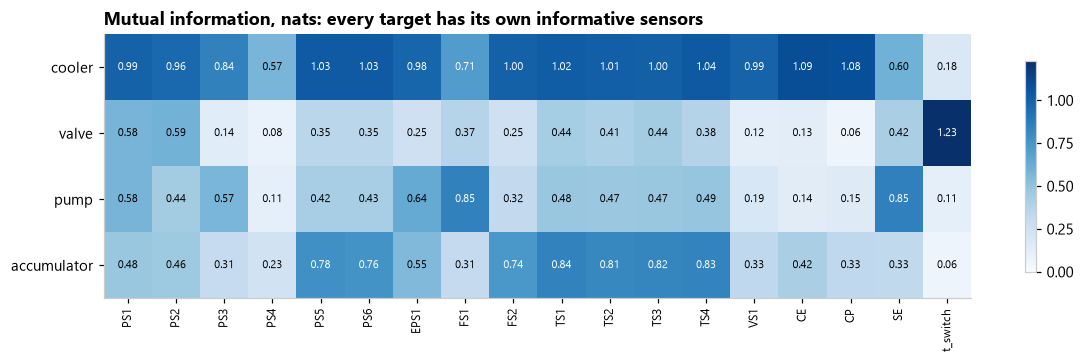

In [37]:
X_all = means.assign(t_switch=t_switch)
TARGETS = ["cooler", "valve", "pump", "accumulator"]

mi = pd.DataFrame({
    target: mutual_info_classif(X_all, profile[target], random_state=0)
    for target in TARGETS
}, index=X_all.columns)

print("top five features by mutual information, per target:")
for target in mi:
    top = mi[target].sort_values(ascending=False).head(5)
    top_text = ", ".join(f"{c} {v:.2f}" for c, v in top.items())
    print(f"  {target:11s}  H = {entropy(profile[target]):.2f} | {top_text}")

fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(mi.T, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(mi.index)), mi.index, rotation=90, fontsize=8)
ax.set_yticks(range(len(TARGETS)), TARGETS)
for i in range(len(TARGETS)):
    for j in range(len(mi.index)):
        v = mi.iloc[j, i]
        text_colour = "white" if v > 0.7 else "black"
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color=text_colour)
ax.grid(False)
ax.set_title("Mutual information, nats: every target has its own informative sensors")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

A feature is informative about a question, not in general. `CE` leads for the cooler and scores
0.13 for the valve. `t_switch` is nearly perfect for the valve ($I \approx H$) and scores 0.18
for the cooler. The pump shows in `SE` and `FS1`, the accumulator in the temperatures.

Ask "which sensors matter?" and the honest reply is "for which fault?".

The same ranking on the 188 engineered features, for the three hard targets:

In [38]:
mi_wide = pd.DataFrame({
    target: mutual_info_classif(wide, profile[target], random_state=0)
    for target in ["valve", "pump", "accumulator"]
}, index=wide.columns)

for target in mi_wide:
    top = mi_wide[target].sort_values(ascending=False).head(6)
    top_text = ", ".join(f"{c} {v:.2f}" for c, v in top.items())
    print(f"{target:11s}: {top_text}")

valve      : t_switch 1.23, PS2_seg0 1.19, FS1_seg0 0.86, PS3_seg0 0.81, SE_seg0 0.75, PS2_std 0.66
pump       : SE_seg4 0.94, SE_seg3 0.93, FS1_seg4 0.89, FS1_seg3 0.87, SE_seg2 0.86, FS1_seg2 0.86
accumulator: TS4_max 0.85, TS4_seg3 0.85, TS4_seg2 0.85, TS4_seg4 0.85, TS1_mean 0.84, TS4_min 0.84


With no physics given, the filter still finds the valve in `PS2_seg0`, the first 10-second
step, which contains the switching moment. It ranks it just below our hand-made `t_switch`. The
pump shows best in the middle steps of `SE` and `FS1`.

## 5.5 A short list, and the check that it works

Pick five features for the cooler: best mutual information first, skipping any feature
correlated above 0.95 with one already chosen. Then do the only test that counts: cluster again
and compare.

In [39]:
def short_list(scores, data, n=5, limit=0.95):
    # best score first; skip a feature that copies one already chosen (|r| > limit)
    chosen = []
    for c in scores.sort_values(ascending=False).index:
        if all(abs(data[c].corr(data[k])) <= limit for k in chosen):
            chosen.append(c)
        if len(chosen) == n:
            break
    return chosen


five = short_list(mi["cooler"], X_all)
print("short list for the cooler:", five)

for label, cols in [("all 17 means", SENSORS), ("short list of 5", five)]:
    Zs = StandardScaler().fit_transform(X_all[cols])
    lab = KMeans(4, n_init=10, random_state=0).fit_predict(Zs)
    ari = adjusted_rand_score(profile["cooler"], lab)
    print(f"  K-means k=4 on {label:15s}: ARI cooler {ari:.3f}, "
          f"silhouette {silhouette_score(Zs, lab):.3f}")

short list for the cooler: ['CE', 'TS1', 'PS1', 'VS1', 'EPS1']
  K-means k=4 on all 17 means   : ARI cooler 0.845, silhouette 0.749


  K-means k=4 on short list of 5: ARI cooler 0.847, silhouette 0.784


Five sensors give the same ARI as seventeen and a higher silhouette, 0.78 against 0.75. The
filter removed only near-copies above 0.95. Three of the five (`CE`, `TS1`, `VS1`) still follow
the oil temperature, and for the cooler that is the right signal.

For the valve the list would start with `t_switch`, which alone separates the four states
(section 4.2). A short list always belongs to one question.

---

## Summary

| step | tool | what to remember |
|---|---|---|
| problem statement | object, features, answer, model, metric | decide what a new case is before you split |
| scaling | `StandardScaler` | without it the distance is the sensor with the largest numbers |
| K-means | `KMeans`, `n_init=10` | elbow and silhouette to pick $k$; centres in physical units for the engineer |
| DBSCAN | `DBSCAN`, k-distance plot | the number of clusters is an output; noise marks transients |
| comparing partitions | `pd.crosstab`, `adjusted_rand_score` | numbering does not matter, agreement does |
| pattern recognition | nearest centroid | a few labelled cycles name the clusters |
| feature engineering | physics first | one switching time beat 17 averages for the valve |
| variance threshold | `VarianceThreshold` | only on scaled data: variance has units |
| correlation filter | `df.corr()` | one physical factor, one feature |
| mutual information | `mutual_info_classif` | informative *about a target* |

## Further reading

- Gaussian mixtures and the EM algorithm. Each cluster becomes a Gaussian with its own
  covariance, so groups may be stretched along a direction and differ in size, and each cycle
  gets a probability of belonging to every cluster. EM fits it with the same two steps as
  Lloyd's algorithm, a soft assignment and then weighted means and covariances. On a plant the
  soft membership marks cycles caught between two regimes, and the likelihood of a new cycle
  works as an anomaly score. In scikit-learn it is `GaussianMixture`; C. M. Bishop, *Pattern
  Recognition and Machine Learning* (2006), chapter 9, derives it.

Next: Practice 2, `practice_2.ipynb`. The same methods on the Tennessee Eastman chemical
process: 52 variables, six operating modes, and a control system that hides some of the faults
from you.